In [6]:
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime

In [7]:

data_path = Path(r"C:\Users\Alfonso(FonsoP)Panli\Desktop\Projects\Disengagement\Data")

# Read Data
sc_engagement_raw = pd.read_excel(Path(data_path) / 'SC Engagement List2026-10-07 07_48_09.xlsx')
mystaff_raw = pd.read_excel(Path(data_path) / 'CONFIDENTIAL Mystaff 10052026.xlsx', sheet_name='MyStaff')


In [16]:

today = pd.Timestamp.today().normalize()

# Data Formatting
sc_engagement = sc_engagement_raw.copy()
sc_engagement['engagement_date'] = pd.to_datetime(sc_engagement['Engagement Date'])
sc_engagement['disengagement_date'] = pd.to_datetime(sc_engagement['Disengagement Date'], errors="coerce").fillna(today)

mystaff_cols = ['Shortcode', 'Region', 'Industry Roll Up', 'Industry Hubspot', 'Custom_Division (Hubspot)']
mystaff = mystaff_raw[mystaff_cols].copy()

In [22]:
# ============================================================
# Engagement pipeline (single script, run top to bottom)
#   1. Events + headcount timeline
#   2. Engagement summary (incl. churn grace period, reactivation, held milestones)
#   3. Region / industry merge + cohort helpers + rollups
#   4. Seat-path cohorts
#   5. Early-signal features
# Needs in memory: sc_engagement, mystaff, today
# Safe to re-run: `summary` is rebuilt from scratch each time.
# ============================================================
import numpy as np
import pandas as pd

# ---------------- Config (confirm with stakeholders) ----------------
exit_statuses = ["Resigned", "AWOL", "Dismissed"]   # attrition exits (Resigned is usually voluntary; label with care)
SEAT_TARGET   = 5
LAUNCH_DAYS   = 14     # hires within this window = the "launch" team (handles staggered onboarding)
FAST_DAYS     = 90     # reached target within this = Fast
SLOW_DAYS     = 365    # reached within this = Slow; later = Very slow
MIN_OBS_NEVER = 365    # active accounts need this much history to be called "Never reached"
EARLY_WINDOWS = (0, LAUNCH_DAYS, 30, 60, 90)
ROLE_COL      = None   # e.g. "Department" / "Job Family" once available in sc_engagement
ROLE_MAP      = {}     # raw title/department -> standard function, e.g. {"CSR": "Customer Support"}
HEADCOUNT_MILESTONES = (5, 10, 20)   # days_till_N_headcount is built for each N (must include SEAT_TARGET, 10 and 20)
RAMP_WINDOWS  = {5:  (90, 180, 270, 365),  # reached_5_in_Nd flags:  ~3, 6, 9, 12 months
                 10: (90, 180, 365, 730),  # reached_10_in_Nd flags: ~3, 6, 12, 24 months
                 20: (365, 730, 1095)}     # reached_20_in_Nd flags: ~12, 24, 36 months
SMALL_START   = (1, 2)   # launch-team size (headcount at day LAUNCH_DAYS) that counts as a "small starter"
GROWTH_DAYS   = 730      # window for the growth tier and the high-growth target (~24 months)
ACTIVE_FILL_DATE    = None   # date your extract puts in disengagement_date for still-active staff (None = today)
ACTIVE_STATUSES     = []     # Employment Status values that always mean "still active", e.g. ["Active"]
CHURN_GRACE_DAYS    = 30     # a zero-headcount gap must last LONGER than this to count as churn (shorter = backfill)
MILESTONE_HOLD_DAYS = 30     # headcount must stay at N+ at least this long for a milestone to count (0 = first touch)

# ============================================================
# Setup
# ============================================================
today_ts = pd.Timestamp(today)

sc_engagement["engagement_date"] = pd.to_datetime(sc_engagement["engagement_date"])
sc_engagement["disengagement_date"] = pd.to_datetime(sc_engagement["disengagement_date"])

# --- Who is still active? (explicit, instead of "disengagement_date == today") ---
fill_ts = pd.Timestamp(ACTIVE_FILL_DATE) if ACTIVE_FILL_DATE else today_ts
dd = sc_engagement["disengagement_date"]
is_active = dd.isna() | (dd >= today_ts) | (dd == fill_ts)   # blank, today/future-dated (e.g. notice period), or fill date
if ACTIVE_STATUSES:
    is_active |= sc_engagement["Employment Status"].isin(ACTIVE_STATUSES)
sc_engagement["is_active"] = is_active

# Hires that haven't started yet are left out of every count
future_start = sc_engagement["engagement_date"] > today_ts
src = sc_engagement[~future_start].copy()

# Data checks
top_dates = dd.value_counts().head(3)
print("Most common disengagement dates:\n", top_dates.to_string())
print(f"Active hires: {int(is_active.sum())} | future-dated exits treated as active: {int((dd > today_ts).sum())} | "
      f"blank disengagement dates: {int(dd.isna().sum())} | future starts excluded: {int(future_start.sum())}")
if len(top_dates):
    top = top_dates.index[0]
    if top_dates.iloc[0] > 0.2 * len(dd) and not (top >= today_ts or top == fill_ts):
        print(f"WARNING: {top.date()} appears on {top_dates.iloc[0]} rows but is treated as a real exit date. "
              "If it is the extract's 'still active' fill date, set ACTIVE_FILL_DATE to it.")

# ============================================================
# Build events
# ============================================================
# +1 when someone starts
starts = (src[["Shortcode", "engagement_date"]]
          .rename(columns={"engagement_date": "date"})
          .copy())
starts["Employment Status"] = "Start Employment"
starts["delta"] = 1
starts["is_attrition"] = 0
starts["is_exit"] = 0

# -1 when someone ends (still-active hires, including future-dated exits, are skipped)
ended = src[~src["is_active"]]
ends = (ended[["Shortcode", "disengagement_date", "Employment Status"]]
        .rename(columns={"disengagement_date": "date"})
        .copy())
ends["delta"] = -1
ends["is_attrition"] = ends["Employment Status"].isin(exit_statuses).astype(int)
ends["is_exit"] = 1                                     # any disengagement

events = pd.concat([starts, ends], ignore_index=True)

# ============================================================
# Headcount timeline
# ============================================================
timeline = (
    events.groupby(["Shortcode", "date"], as_index=False)
          .agg(delta=("delta", "sum"),
               is_attrition=("is_attrition", "max"),   # 1 if any attrition exit on that date
               is_exit=("is_exit", "max"))             # 1 if any exit on that date
          .sort_values(["Shortcode", "date"])
          .reset_index(drop=True)
)
timeline["active_staff"] = timeline.groupby("Shortcode")["delta"].cumsum()
timeline = timeline.drop(columns="delta")

# ============================================================
# Engagement summary
# ============================================================
# --- Core start / end info ---
summary = (
    timeline.groupby("Shortcode")
            .agg(start_date=("date", "first"),
                 employee_count_at_start=("active_staff", "first"),
                 last_date=("date", "last"),
                 current_headcount=("active_staff", "last"))
            .reset_index()
)

summary["start_cohort"] = summary["start_date"].dt.to_period("Q")
summary["days_observed"] = (today_ts - summary["start_date"]).dt.days

# --- Zero-headcount spells: churn vs backfill gap ---
# A spell starts when headcount goes from >0 to 0 and ends when it comes back above 0
# (a same-day start + exit at the very beginning is not a spell).
# Spell longer than CHURN_GRACE_DAYS          -> churn (and a reactivation if it later ended)
# Completed spell of CHURN_GRACE_DAYS or less -> backfill gap, not churn
# Ongoing spell of CHURN_GRACE_DAYS or less   -> churn pending (account still counted as active)
tl = timeline[["Shortcode", "date", "active_staff"]].copy()   # already sorted by Shortcode, date
prev = tl.groupby("Shortcode")["active_staff"].shift()        # NaN on each account's first row
pos = tl["active_staff"].gt(0).astype(int)
had_staff_before = pos.groupby(tl["Shortcode"]).cumsum() - pos

tl["churn_point"]        = (tl["active_staff"].le(0) & prev.gt(0)).astype(int)
tl["reactivation_point"] = (tl["active_staff"].gt(0) & prev.le(0) & had_staff_before.gt(0)).astype(int)
tl["next_return"] = (tl["date"].where(tl["reactivation_point"] == 1)
                       .groupby(tl["Shortcode"]).bfill())

spells = (tl.loc[tl["churn_point"] == 1, ["Shortcode", "date", "next_return"]]
            .rename(columns={"date": "zero_start"}))
spells["ongoing"]  = spells["next_return"].isna()
spells["gap_days"] = (spells["next_return"].fillna(today_ts) - spells["zero_start"]).dt.days
spells["is_churn"] = spells["gap_days"] > CHURN_GRACE_DAYS
by_sc = spells["Shortcode"]

summary["first_zero_date"]    = summary["Shortcode"].map(spells.groupby("Shortcode")["zero_start"].min())
summary["days_to_first_zero"] = (summary["first_zero_date"] - summary["start_date"]).dt.days
summary["first_churn_date"]   = summary["Shortcode"].map(
    spells[spells["is_churn"]].groupby("Shortcode")["zero_start"].min())
summary["days_to_first_churn"] = (summary["first_churn_date"] - summary["start_date"]).dt.days
summary["n_backfill_gaps"] = summary["Shortcode"].map(
    (~spells["is_churn"] & ~spells["ongoing"]).groupby(by_sc).sum()).fillna(0).astype(int)
summary["n_reactivations"] = summary["Shortcode"].map(
    (spells["is_churn"] & ~spells["ongoing"]).groupby(by_sc).sum()).fillna(0).astype(int)
summary["reactivated"]     = summary["n_reactivations"].gt(0)          # boolean
summary["churn_pending"]   = summary["Shortcode"].isin(
    spells.loc[spells["ongoing"] & ~spells["is_churn"], "Shortcode"]).astype(int)

# Active = has staff today, or is inside the grace period after dropping to 0
summary["engagement_active"] = (summary["current_headcount"].gt(0)
                                | summary["churn_pending"].eq(1)).astype(int)
summary["end_date"] = summary["last_date"].where(summary["engagement_active"] == 0, pd.NaT)
summary["engagement_timespan_days"] = (
    (summary["end_date"] - summary["start_date"]).dt.days.astype("Int64")
)

# --- Peak headcount ---
peak_idx = timeline.groupby("Shortcode")["active_staff"].idxmax()
peak = (timeline.loc[peak_idx, ["Shortcode", "date", "active_staff"]]
                .rename(columns={"date": "peak_date", "active_staff": "peak_headcount"}))
summary = summary.merge(peak, on="Shortcode", how="left")
summary["days_to_peak"] = (summary["peak_date"] - summary["start_date"]).dt.days

# --- Headcount milestones ---
# A milestone counts from the first day of the first run at N+ that lasted MILESTONE_HOLD_DAYS or more.
# Brief spikes (e.g. a replacement overlapping with the person leaving) don't count.
# A run still going today counts only once it has lasted MILESTONE_HOLD_DAYS.
def first_held_date(n, hold):
    sc = timeline["Shortcode"]
    above = timeline["active_staff"] >= n
    prev_above = above.groupby(sc).shift(fill_value=False).astype(bool)
    run_start = above & ~prev_above
    run_end = (timeline["date"].where(~above & prev_above)          # first day back below N
                               .groupby(sc).bfill())
    runs = pd.DataFrame({"Shortcode": sc[run_start],
                         "start": timeline.loc[run_start, "date"],
                         "end": run_end[run_start].fillna(today_ts)})
    runs = runs[(runs["end"] - runs["start"]).dt.days >= hold]
    return runs.groupby("Shortcode")["start"].min()

for n in HEADCOUNT_MILESTONES:
    held = first_held_date(n, MILESTONE_HOLD_DAYS)
    touched = first_held_date(n, 0)
    summary[f"days_till_{n}_headcount"] = (
        (summary["Shortcode"].map(held) - summary["start_date"])
        .dt.days.astype("Int64")
    )
    later = (held.reindex(touched.index) > touched).sum()
    print(f"{n}+ seats: touched by {len(touched)} accounts, held {MILESTONE_HOLD_DAYS}+ days by {len(held)} "
          f"({len(touched) - len(held)} never held; {later} held only on a later run)")

# --- Attrition volume ---
hires = src.groupby("Shortcode").size()
exits = ends.groupby("Shortcode").size()
attr_exits = ends.groupby("Shortcode")["is_attrition"].sum()

summary["total_hires"] = summary["Shortcode"].map(hires)
summary["total_exits"] = summary["Shortcode"].map(exits).fillna(0).astype(int)
summary["attrition_exits"] = summary["Shortcode"].map(attr_exits).fillna(0).astype(int)
summary["attrition_rate"] = (summary["attrition_exits"] / summary["total_hires"]).round(3)

by_type = (ends[ends["is_attrition"] == 1]
           .pivot_table(index="Shortcode", columns="Employment Status",
                        values="date", aggfunc="count", fill_value=0)
           .reindex(columns=exit_statuses, fill_value=0)   # all 3 columns always present
           .add_prefix("exits_")
           .reset_index())
summary = summary.merge(by_type, on="Shortcode", how="left")
type_cols = [f"exits_{s}" for s in exit_statuses]
summary[type_cols] = summary[type_cols].fillna(0).astype(int)

# --- Attrition timing ---
t = timeline.merge(summary[["Shortcode", "start_date"]], on="Shortcode")
t["days_since_start"] = (t["date"] - t["start_date"]).dt.days
attr = t[t["is_attrition"] > 0]

first_attr = attr.groupby("Shortcode")["days_since_start"].min()
summary["days_to_first_attrition"] = summary["Shortcode"].map(first_attr).astype("Int64")

for d in (30, 60, 90):
    flagged = attr.loc[attr["days_since_start"] <= d, "Shortcode"].unique()
    summary[f"eligible_{d}d"] = (summary["days_observed"] >= d).astype(int)
    summary[f"attrition_within_{d}d"] = summary["Shortcode"].isin(flagged).astype(int)

# --- Early disengagement timing (any exit) ---
exit_ev = t[t["is_exit"] > 0]

first_exit = exit_ev.groupby("Shortcode")["days_since_start"].min()
summary["days_to_first_disengagement"] = summary["Shortcode"].map(first_exit).astype("Int64")

for d in (30, 60, 90):
    flagged = exit_ev.loc[exit_ev["days_since_start"] <= d, "Shortcode"].unique()
    summary[f"disengaged_within_{d}d"] = summary["Shortcode"].isin(flagged).astype(int)

# --- Column order ---
col_order = [
    # Identity
    "Shortcode", "start_cohort",
    # Lifecycle
    "start_date", "end_date", "engagement_active",
    "engagement_timespan_days", "days_observed",
    # Churn / reactivation
    "churn_pending", "first_churn_date", "days_to_first_churn",
    "reactivated", "n_reactivations", "n_backfill_gaps",
    "first_zero_date", "days_to_first_zero",
    # Headcount growth
    "employee_count_at_start", "current_headcount",
    "peak_headcount", "peak_date", "days_to_peak",
    *[f"days_till_{n}_headcount" for n in HEADCOUNT_MILESTONES],
    # Attrition volume
    "total_hires", "total_exits", "attrition_exits", "attrition_rate",
    *type_cols,
    # Attrition / disengagement timing
    "days_to_first_attrition", "days_to_first_disengagement",
    "eligible_30d", "attrition_within_30d", "disengaged_within_30d",
    "eligible_60d", "attrition_within_60d", "disengaged_within_60d",
    "eligible_90d", "attrition_within_90d", "disengaged_within_90d",
]
summary = summary[col_order]

# ============================================================
# Merge region / industry and move next to Shortcode
# ============================================================
print(summary.shape)
summary = summary.merge(mystaff, how="left")
move = ["Region", "Industry Roll Up", "Industry Hubspot"]
rest = [c for c in summary.columns if c not in ["Shortcode"] + move]
summary = summary[["Shortcode"] + move + rest]
print(summary.shape)

# ============================================================
# Cohort helpers
# ============================================================
summary["start_year"] = summary["start_date"].dt.year
summary["start_size_bucket"] = pd.cut(
    summary["employee_count_at_start"],
    bins=[0, 2, 5, float("inf")],
    labels=["1 to 2", "3 to 5", "6+"],
)

# Fixed-window ramp flags (eligible-only: NaN if not enough time observed)
# 90 / 180 / 270 / 365 days = roughly 3 / 6 / 9 / 12 months
for n, windows in RAMP_WINDOWS.items():
    for d in windows:
        hit = (summary[f"days_till_{n}_headcount"] <= d).fillna(False).astype(int)
        summary[f"reached_{n}_in_{d}d"] = hit.where(summary["days_observed"] >= d)

# Mask attrition and disengagement flags the same way
for d in (30, 60, 90):
    summary[f"attr_{d}d_elig"] = summary[f"attrition_within_{d}d"].where(
        summary[f"eligible_{d}d"] == 1)
    summary[f"disengaged_{d}d_elig"] = summary[f"disengaged_within_{d}d"].where(
        summary[f"eligible_{d}d"] == 1)

# ============================================================
# Sanity checks
# ============================================================
for d in (30, 60, 90):
    # attrition is a subset of disengagement, so this should be 0 rows
    bad = summary[summary[f"attrition_within_{d}d"] > summary[f"disengaged_within_{d}d"]]
    print(f"{d}d: attrition > disengagement rows = {len(bad)}")

    elig = summary[summary[f"eligible_{d}d"] == 1]
    print(f"{d}d: eligible={len(elig)}, "
          f"attrition events={elig[f'attrition_within_{d}d'].sum()}, "
          f"disengagement events={elig[f'disengaged_within_{d}d'].sum()}")

# Reactivation: every reactivated account must have churned first
assert summary.loc[summary["reactivated"], "first_churn_date"].notna().all(), \
    "reactivated accounts must have a first churn date"
print(f"Zero-headcount gaps: {len(spells)} | backfills (<= {CHURN_GRACE_DAYS}d): "
      f"{int((~spells['is_churn'] & ~spells['ongoing']).sum())} | churns: {int(spells['is_churn'].sum())} | "
      f"pending: {int(summary['churn_pending'].sum())}")
print(f"Reactivated accounts: {summary['reactivated'].sum()} of {len(summary)}")
reactivation_by_status = pd.crosstab(summary["reactivated"], summary["engagement_active"],
                                     rownames=["reactivated"], colnames=["engagement_active"],
                                     margins=True)
reactivation_by_region = (summary.groupby("Region")["reactivated"]
                                 .agg(accounts="count", reactivated="sum", pct="mean").round(3))
print(reactivation_by_status, "\n")
print(reactivation_by_region, "\n")

# ============================================================
# Optional: replaces the old `ramp` block
# ============================================================
n_staff_start = 3
ramp = summary[(summary["employee_count_at_start"] < n_staff_start)
               & summary["days_till_5_headcount"].notna()]

# ============================================================
# Cohort rollup (reusable for any grouping)
# ============================================================
def rollup(df, by, min_n=20):
    out = df.groupby(by, observed=True).agg(
        engagements=("Shortcode", "count"),
        pct_active=("engagement_active", "mean"),
        pct_reactivated=("reactivated", "mean"),
        median_start_size=("employee_count_at_start", "median"),
        median_peak=("peak_headcount", "median"),
        reached_5_90d=("reached_5_in_90d", "mean"),
        reached_5_180d=("reached_5_in_180d", "mean"),
        reached_5_270d=("reached_5_in_270d", "mean"),
        reached_5_365d=("reached_5_in_365d", "mean"),
        n_365d_eligible=("reached_5_in_365d", "count"),   # accounts observed 365+ days
        reached_10_180d=("reached_10_in_180d", "mean"),
        reached_10_730d=("reached_10_in_730d", "mean"),
        reached_20_730d=("reached_20_in_730d", "mean"),
        attr_30d=("attr_30d_elig", "mean"),
        attr_60d=("attr_60d_elig", "mean"),
        attr_90d=("attr_90d_elig", "mean"),
        disengaged_30d=("disengaged_30d_elig", "mean"),
        disengaged_60d=("disengaged_60d_elig", "mean"),
        disengaged_90d=("disengaged_90d_elig", "mean"),
        n_90d_eligible=("eligible_90d", "sum"),
        total_hires=("total_hires", "sum"),
        attrition_exits=("attrition_exits", "sum"),
        resigned=("exits_Resigned", "sum"),
        awol=("exits_AWOL", "sum"),
        dismissed=("exits_Dismissed", "sum"),
    )
    out["attrition_per_hire"] = (out["attrition_exits"] / out["total_hires"]).round(3)
    return out[out["engagements"] >= min_n].round(3)

by_year     = rollup(summary, "start_year")
by_region   = rollup(summary, ["Region", "start_year"])
by_industry = rollup(summary, ["Industry Roll Up", "start_year"])
by_size     = rollup(summary, "start_size_bucket")
by_reg_ind  = rollup(summary, ["Region", "Industry Roll Up"], min_n=30)

# ============================================================
# STEP 1: Seat-path cohorts (mutually exclusive)
# ============================================================
r5     = summary[f"days_till_{SEAT_TARGET}_headcount"].astype("float")   # NaN = never reached
active = summary["engagement_active"].eq(1)
obs    = summary["days_observed"]

conds = [
    r5 <= LAUNCH_DAYS,                                  # started at scale; not a "ramp" story
    r5 <= FAST_DAYS,
    r5 <= SLOW_DAYS,
    r5 > SLOW_DAYS,
    r5.isna() & ~active,
    r5.isna() & active & (obs >= MIN_OBS_NEVER),
]
labels = [
    "0 Launched at 5+",
    "1 Fast",
    "2 Slow",
    "3 Very slow",
    "4 Never reached - churned",
    "5 Never reached - active",
]
summary["seat_path"] = np.select(conds, labels, default="6 Too early to tell")

# Map onto the four groups in the original ask (+ two exclusion buckets)
ask_map = {
    "0 Launched at 5+":          "Launched at 5+ (exclude from ramp)",
    "1 Fast":                    "Reached 5 quickly",
    "2 Slow":                    "Reached 5 slowly",
    "3 Very slow":               "Reached 5 slowly",
    "4 Never reached - churned": "Churned before 5",
    "5 Never reached - active":  "Never reached 5",
    "6 Too early to tell":       "Too early (exclude)",
}
summary["ask_cohort"] = summary["seat_path"].map(ask_map)

# Churn is an overlay, not a path, so "reached 5 then churned" stays visible
summary["churned"]         = (~active).astype(int)
summary["churned_after_5"] = (r5.notna() & ~active).astype(int)
summary["date_reached_5"]  = summary["start_date"] + pd.to_timedelta(r5, unit="D")
summary["days_after_5"]    = (summary["end_date"].fillna(today_ts) - summary["date_reached_5"]).dt.days
summary["tenure_days"]     = summary["engagement_timespan_days"].astype("float").fillna(obs)

# --- Cohort views, APAC and AMER side by side ---
cohort_counts = pd.crosstab(summary["Region"], summary["ask_cohort"], margins=True)
cohort_mix    = pd.crosstab(summary["Region"], summary["ask_cohort"], normalize="index").round(3)

# Censoring check: recent start years should be heavy on "Too early"
path_by_year  = pd.crosstab(summary["start_year"], summary["seat_path"])

path_profile = (summary.groupby(["Region", "seat_path"])
                       .agg(accounts=("Shortcode", "count"),
                            pct_churned=("churned", "mean"),
                            pct_reactivated=("reactivated", "mean"),
                            median_start=("employee_count_at_start", "median"),
                            median_peak=("peak_headcount", "median"),
                            median_current=("current_headcount", "median"),
                            median_tenure_days=("tenure_days", "median"),
                            median_days_to_5=("days_till_5_headcount", "median"),
                            median_days_after_5=("days_after_5", "median"))
                       .round(3))

# ============================================================
# STEP 2: Early-signal features (observable in the first 0-90 days)
# ============================================================
keep = ["Shortcode", "engagement_date", "disengagement_date", "Employment Status", "is_active"]
if ROLE_COL:
    keep.append(ROLE_COL)

eng = (src[keep]
       .merge(summary[["Shortcode", "start_date"]], on="Shortcode", how="inner")
       .sort_values(["Shortcode", "engagement_date"]))
eng["hire_day"]     = (eng["engagement_date"] - eng["start_date"]).dt.days
eng["ended"]        = ~eng["is_active"]
eng["exit_day"]     = (eng["disengagement_date"] - eng["start_date"]).dt.days.where(eng["ended"])
eng["is_attr_exit"] = eng["ended"] & eng["Employment Status"].isin(exit_statuses)

# --- Windowed counts (headcount semantics match the timeline: exit on day d is off-seat) ---
frames = []
for d in EARLY_WINDOWS:
    e = eng[eng["hire_day"] <= d]
    exited = e["exit_day"] <= d                        # NaN (still active) -> False
    by = e["Shortcode"]
    frames.append(pd.DataFrame({
        f"hc_{d}d":         (~exited).groupby(by).sum(),
        f"hires_{d}d":      e.groupby("Shortcode").size(),
        f"new_hires_{d}d":  (e["hire_day"] > 0).groupby(by).sum(),     # seats added after day 0
        f"exits_{d}d":      exited.groupby(by).sum(),
        f"attr_exits_{d}d": (exited & e["is_attr_exit"]).groupby(by).sum(),
        f"hire_waves_{d}d": e.groupby("Shortcode")["hire_day"].nunique(),  # distinct hiring dates
    }))
feat = pd.concat(frames, axis=1).reindex(summary["Shortcode"]).astype("float")
feat.index.name = "Shortcode"

# Mask windows the account hasn't lived through yet
obs_by_code = summary.set_index("Shortcode")["days_observed"].reindex(feat.index)
for d in EARLY_WINDOWS:
    cols = [c for c in feat.columns if c.endswith(f"_{d}d")]
    feat.loc[obs_by_code < d, cols] = np.nan

# Derived signals
for d in EARLY_WINDOWS[1:]:
    feat[f"net_growth_{d}d"]      = feat[f"hc_{d}d"] - feat["hc_0d"]
    feat[f"added_seat_{d}d"]      = (feat[f"new_hires_{d}d"] > 0).astype(float).where(feat[f"new_hires_{d}d"].notna())
    feat[f"early_attr_rate_{d}d"] = feat[f"attr_exits_{d}d"] / feat[f"hires_{d}d"]

# Sanity check: day-0 headcount should match the timeline-based start count
mismatch = summary.set_index("Shortcode")["employee_count_at_start"].ne(feat["hc_0d"]).sum()
print(f"hc_0d vs employee_count_at_start mismatches: {mismatch}")

# --- Function / role features (activate once ROLE_COL exists) ---
role_outcomes = []
if ROLE_COL:
    fn = eng[ROLE_COL].map(ROLE_MAP).fillna(eng[ROLE_COL]) if ROLE_MAP else eng[ROLE_COL]
    eng["function"] = fn.fillna("Unknown")

    # Initial function: most common among launch hires; ties -> earliest hired
    launch = eng[eng["hire_day"] <= LAUNCH_DAYS]
    init_fn = (launch.groupby(["Shortcode", "function"])
                     .agg(n=("hire_day", "size"), first=("hire_day", "min"))
                     .reset_index()
                     .sort_values(["Shortcode", "n", "first"], ascending=[True, False, True])
                     .drop_duplicates("Shortcode")
                     .set_index("Shortcode")["function"])
    feat["initial_function"] = init_fn
    feat["launched_multi_function"] = (launch.groupby("Shortcode")["function"].nunique() > 1).astype(float)

    for d in EARLY_WINDOWS[1:]:
        n_fn = eng[eng["hire_day"] <= d].groupby("Shortcode")["function"].nunique()
        feat[f"n_functions_{d}d"] = n_fn.reindex(feat.index).where(obs_by_code >= d)

    # Outcomes (NOT early features): time to 2nd function, expansion type
    fn_first = (eng.groupby(["Shortcode", "function"])["hire_day"].min()
                   .reset_index().sort_values(["Shortcode", "hire_day"]))
    fn_first["rank"] = fn_first.groupby("Shortcode").cumcount()
    feat["days_to_2nd_function"] = fn_first[fn_first["rank"] == 1].set_index("Shortcode")["hire_day"]

    post = eng[eng["hire_day"] > LAUNCH_DAYS].copy()
    post["same_fn"] = post["function"].eq(post["Shortcode"].map(init_fn))
    exp = post.groupby("Shortcode").agg(post_launch_hires=("same_fn", "size"),
                                        same_fn_hires=("same_fn", "sum"))
    exp["pct_expansion_same_function"] = exp["same_fn_hires"] / exp["post_launch_hires"]
    feat = feat.join(exp)

    role_outcomes = ["days_to_2nd_function", "post_launch_hires",
                     "same_fn_hires", "pct_expansion_same_function"]

summary = summary.merge(feat.reset_index(), on="Shortcode", how="left", validate="one_to_one")

# ============================================================
# STEP 3: High-growth framing (small starters -> 5 / 10 / 20 seats)
# ============================================================
# Launch-team size: headcount at day LAUNCH_DAYS, so staggered onboarding in the first
# two weeks counts as one launch (blank if the account is younger than LAUNCH_DAYS)
summary["launch_size"] = summary[f"hc_{LAUNCH_DAYS}d"]
summary["launch_size_bucket"] = pd.cut(
    summary["launch_size"],
    bins=[-np.inf, 0, 2, 4, np.inf],
    labels=["0 (no staff)", "1 to 2", "3 to 4", "5+"],
)
lo, hi = SMALL_START
summary["small_starter"] = summary["launch_size"].between(lo, hi).astype(int).where(summary["launch_size"].notna())

# Growth tier: highest milestone reached within GROWTH_DAYS (blank if not observed that long)
T = GROWTH_DAYS
d5, d10, d20 = (summary[f"days_till_{n}_headcount"].astype("float") for n in (5, 10, 20))
tier = np.select([d20 <= T, d10 <= T, d5 <= T],
                 ["4 Reached 20+", "3 Reached 10+", "2 Reached 5+"], default="1 Under 5")
summary[f"growth_tier_{T}d"] = pd.Series(tier, index=summary.index).where(summary["days_observed"] >= T)

# Main modelling target: small starters that reach 10 within GROWTH_DAYS
# (1/0 for small starters observed that long, blank for everyone else)
summary[f"high_growth_10_in_{T}d"] = summary[f"reached_10_in_{T}d"].where(summary["small_starter"] == 1)
# Top tier: small starters that reach 20 within GROWTH_DAYS (expect few; describe rather than model)
summary[f"top_tier_20_in_{T}d"]    = summary[f"reached_20_in_{T}d"].where(summary["small_starter"] == 1)

# Explicit lists to prevent leakage when modelling later
EARLY_FEATURES = (["Region", "Industry Roll Up", "start_year", "start_size_bucket",
                   "launch_size", "launch_size_bucket", "small_starter"]
                  + [c for c in feat.columns if c not in role_outcomes])
OUTCOMES = (["seat_path", "ask_cohort", "churned", "churned_after_5", "days_till_5_headcount",
             "peak_headcount", "current_headcount", "tenure_days", "days_after_5",
             "reactivated", "n_reactivations", "first_zero_date", "days_to_first_zero",
             "churn_pending", "first_churn_date", "days_to_first_churn", "n_backfill_gaps",
             f"growth_tier_{GROWTH_DAYS}d", f"high_growth_10_in_{GROWTH_DAYS}d",
             f"top_tier_20_in_{GROWTH_DAYS}d"]
            + [c for c in summary.columns if c.startswith("reached_")]
            + role_outcomes)

# ============================================================
# First read: do early signals separate the cohorts?
# ============================================================
L = LAUNCH_DAYS
base = summary[~summary["seat_path"].isin(["0 Launched at 5+", "6 Too early to tell"])]

early_by_cohort = (base.groupby(["Region", "ask_cohort"])
                       .agg(accounts=("Shortcode", "count"),
                            **{f"med_hc_{L}d":       (f"hc_{L}d", "median"),
                               "med_hc_30d":         ("hc_30d", "median"),
                               "med_hc_90d":         ("hc_90d", "median"),
                               "pct_added_seat_30d": ("added_seat_30d", "mean"),
                               "pct_added_seat_90d": ("added_seat_90d", "mean"),
                               "med_hire_waves_90d": ("hire_waves_90d", "median"),
                               "early_attr_rate_90d":("early_attr_rate_90d", "mean")})
                       .round(3))

# Conversion: among accounts below 5 at day 30 with a full year observed,
# what share reach 5 within 365 days, by day-30 headcount and early seat adds?
r5_now = summary[f"days_till_{SEAT_TARGET}_headcount"].astype("float")
# reached_5_in_365d is built with the other ramp flags in "Cohort helpers"

pop = summary[summary["reached_5_in_365d"].notna() & ~(r5_now <= 30)].copy()
pop["hc_30d_bucket"] = pd.cut(pop["hc_30d"], bins=[-1, 0, 1, 2, 3, 4],
                              labels=["0 (churned)", "1", "2", "3", "4"])

conv_by_hc30 = (pop.groupby(["Region", "hc_30d_bucket"], observed=True)["reached_5_in_365d"]
                   .agg(accounts="count", pct_reached_5="mean").round(3))
conv_by_add30 = (pop.groupby(["Region", "added_seat_30d"], observed=True)["reached_5_in_365d"]
                    .agg(accounts="count", pct_reached_5="mean").round(3))

# --- High-growth views ---
# Growth-tier mix by launch size (accounts observed GROWTH_DAYS+ only)
tier_by_launch = pd.crosstab(summary["launch_size_bucket"], summary[f"growth_tier_{GROWTH_DAYS}d"],
                             margins=True)

# Small starters: share reaching each milestone by each window, by Region plus an overall row.
# Each rate only uses accounts observed for that window; check the n_ columns before comparing.
ss = summary[summary["small_starter"] == 1]
small_starter_growth = (pd.concat([ss, ss.assign(Region="All")])
                          .groupby("Region")
                          .agg(small_starters=("Shortcode", "count"),
                               reached_5_180d=("reached_5_in_180d", "mean"),
                               reached_5_365d=("reached_5_in_365d", "mean"),
                               reached_10_365d=("reached_10_in_365d", "mean"),
                               reached_10_730d=("reached_10_in_730d", "mean"),
                               reached_20_730d=("reached_20_in_730d", "mean"),
                               n_730d_eligible=("reached_10_in_730d", "count"),
                               n_reached_10_730d=("reached_10_in_730d", "sum"),
                               n_reached_20_730d=("reached_20_in_730d", "sum"))
                          .round(3))

print(tier_by_launch, "\n")
print(small_starter_growth, "\n")
print(cohort_counts, "\n")
print(early_by_cohort, "\n")
print(conv_by_hc30, "\n")
print(conv_by_add30)

Most common disengagement dates:
 disengagement_date
2026-10-14    7478
2021-07-31     131
2024-12-31      85
Active hires: 7478 | future-dated exits treated as active: 0 | blank disengagement dates: 0 | future starts excluded: 0
5+ seats: touched by 587 accounts, held 30+ days by 555 (32 never held; 31 held only on a later run)
10+ seats: touched by 286 accounts, held 30+ days by 270 (16 never held; 20 held only on a later run)
20+ seats: touched by 122 accounts, held 30+ days by 117 (5 never held; 15 held only on a later run)
(2481, 41)
(2481, 45)
30d: attrition > disengagement rows = 0
30d: eligible=2456, attrition events=97, disengagement events=199
60d: attrition > disengagement rows = 0
60d: eligible=2426, attrition events=191, disengagement events=358
90d: attrition > disengagement rows = 0
90d: eligible=2408, attrition events=290, disengagement events=522
Zero-headcount gaps: 1564 | backfills (<= 30d): 92 | churns: 1462 | pending: 10
Reactivated accounts: 98 of 2481
engagement_

In [19]:
summary.to_clipboard()

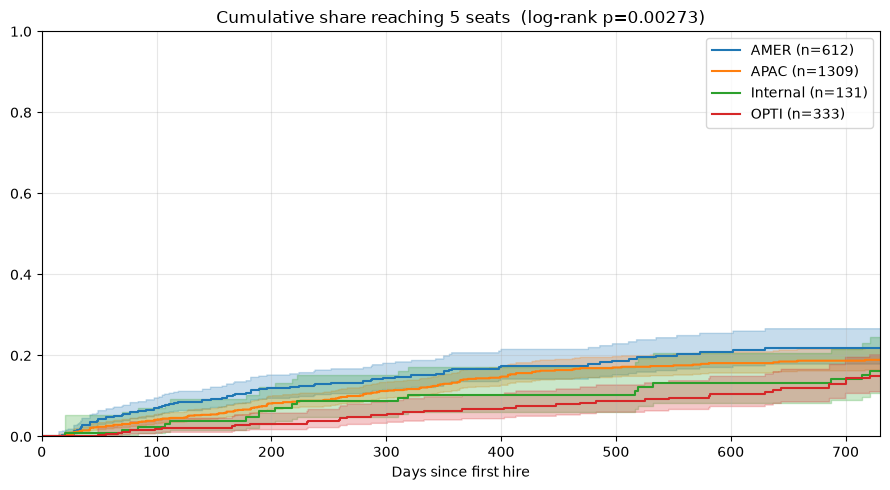

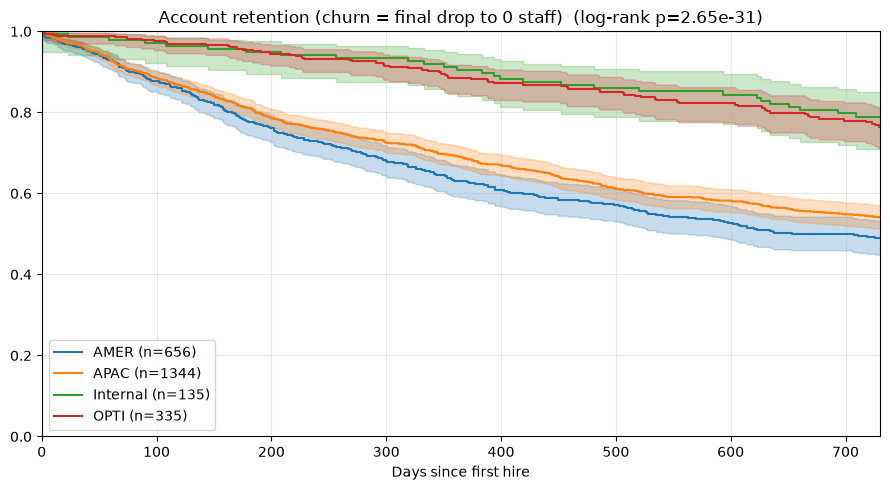

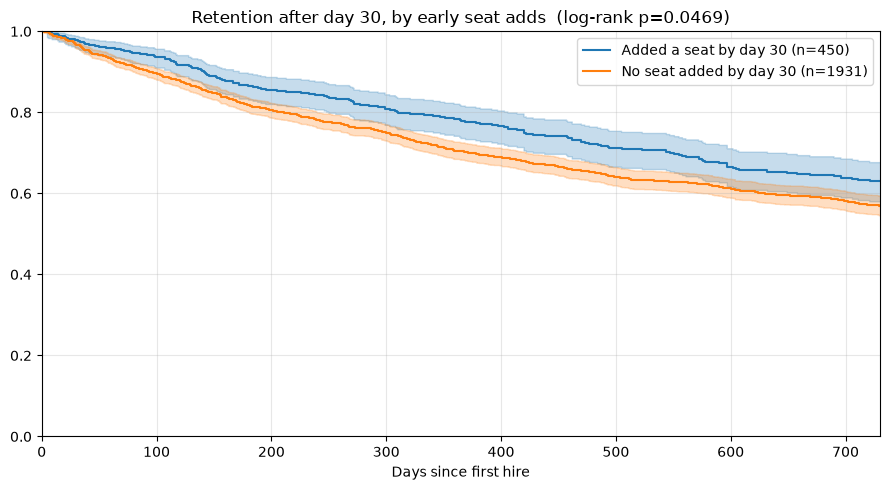

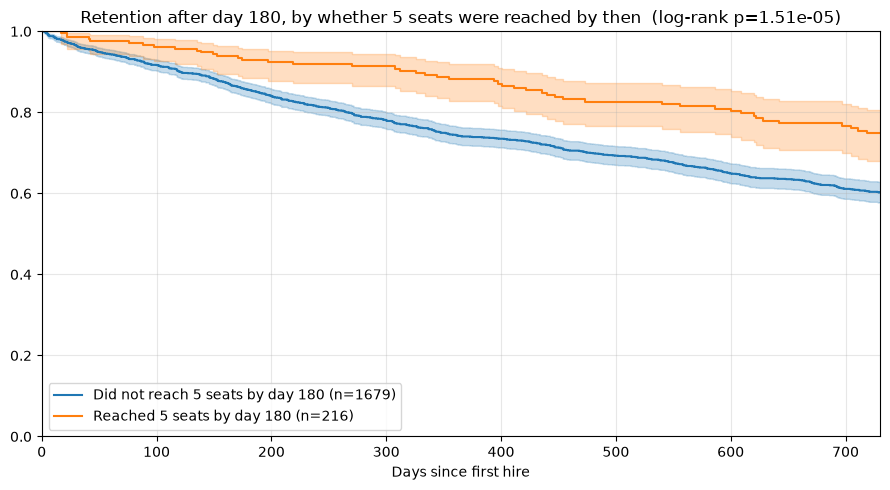

Time to 5 seats (cumulative share, n at risk)
             pct                      n_at_risk                      
day         30     90     180    365       30      90     180    365
group                                                               
AMER      0.014  0.062  0.107  0.168     570.0   481.0  367.0  245.0
APAC      0.012  0.037  0.067  0.140    1244.0  1094.0  896.0  641.0
Internal  0.008  0.023  0.047  0.104     128.0   125.0  119.0  106.0
OPTI      0.000  0.015  0.028  0.064     327.0   317.0  297.0  246.0 

Retention from first hire
             pct                      n_at_risk                      
day         30     90     180    365       30      90     180    365
group                                                               
AMER      0.962  0.888  0.777  0.630     622.0   557.0  458.0  342.0
APAC      0.968  0.897  0.811  0.690    1293.0  1172.0  999.0  791.0
Internal  0.985  0.970  0.948  0.904     133.0   132.0  128.0  122.0
OPTI      0.988  0.979  0.9

In [23]:
# ============================================================
# Kaplan-Meier curves (paste into its own cell)
# Run AFTER engagement_pipeline.py. Needs: summary, SEAT_TARGET
# Requires: pip install lifelines
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

# ---------------- Config ----------------
CHURN_EVENT = "final"   # "first": churn = first zero-headcount gap longer than CHURN_GRACE_DAYS (reactivated accounts DO count as churned)
                        # "final": churn = currently inactive (matches summary["churned"])
LANDMARK    = 30        # day for the landmark curve (must be one of EARLY_WINDOWS, e.g. 30, 60, 90)
RAMP_WINDOW = 180       # day by which an account must reach SEAT_TARGET to count as a "fast ramp" (any day works)
MILESTONES  = (30, 90, 180, 365)
MIN_GROUP_N = 20        # groups smaller than this are not drawn
XMAX        = 730       # x-axis limit in days

# Drop columns created here so re-runs don't produce _x/_y duplicates
_created = {"t5_event", "t5_days", "churn_event", "churn_days"}
summary = summary.drop(columns=[c for c in summary.columns if c in _created])

# ---------------- Durations and event flags ----------------
# Time to SEAT_TARGET. Accounts that never got there are censored when they
# churned or when observation stopped (today), whichever applies.
r5 = summary[f"days_till_{SEAT_TARGET}_headcount"].astype("float")
summary["t5_event"] = r5.notna().astype(int)
summary["t5_days"]  = r5.fillna(summary["tenure_days"])

# Time to churn
if CHURN_EVENT == "first":
    summary["churn_event"] = summary["first_churn_date"].notna().astype(int)
    summary["churn_days"]  = summary["days_to_first_churn"].astype("float").fillna(summary["days_observed"])
else:
    summary["churn_event"] = summary["churned"].astype(int)
    summary["churn_days"]  = summary["tenure_days"]

# ---------------- Plot helper (returns a milestone table with n at risk) ----------------
def km_curves(df, dur, event, group=None, title="", cumulative=False,
              xmax=XMAX, min_n=MIN_GROUP_N, milestones=MILESTONES, max_groups=None):
    d = df[df[dur].notna() & (df[dur] >= 0)].copy()
    if group is None:
        d["_all"] = "All accounts"
        group = "_all"
    d = d[d[group].notna()]
    sizes = d.groupby(group, observed=True).size()
    sizes = sizes[sizes >= min_n]
    if max_groups:
        sizes = sizes.nlargest(max_groups)          # keep the largest groups so the chart stays readable
    d = d[d[group].isin(sizes.index)]
    if d.empty:
        print(f"{title}: no group has {min_n}+ accounts")
        return None

    fig, ax = plt.subplots(figsize=(9, 5))
    rows = []
    for key, g in d.groupby(group, observed=True):
        kmf = KaplanMeierFitter().fit(g[dur], event_observed=g[event], label=f"{key} (n={len(g)})")
        (kmf.plot_cumulative_density if cumulative else kmf.plot_survival_function)(ax=ax)
        for t in milestones:
            s = float(kmf.survival_function_at_times(t).iloc[0])
            rows.append({"group": key, "day": t,
                         "pct": round((1 - s) if cumulative else s, 3),
                         "n_at_risk": int((g[dur] >= t).sum())})

    if d[group].nunique() > 1:
        p = multivariate_logrank_test(d[dur], d[group], d[event]).p_value
        title = f"{title}  (log-rank p={p:.3g})"
    ax.set(title=title, xlabel="Days since first hire", xlim=(0, xmax), ylim=(0, 1))
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(rows).pivot(index="group", columns="day", values=["pct", "n_at_risk"])

# ---------------- The curves ----------------
# 1) Time to 5 seats. Exclude accounts that launched at 5+ (no ramp to measure).
ramp_pop = summary[summary["seat_path"] != "0 Launched at 5+"]
km_t5 = km_curves(ramp_pop, "t5_days", "t5_event", "Region",
                  f"Cumulative share reaching {SEAT_TARGET} seats", cumulative=True)

# 2) Time to churn (retention curve)
km_churn = km_curves(summary, "churn_days", "churn_event", "Region",
                     f"Account retention (churn = {CHURN_EVENT} drop to 0 staff)")

# 3) Landmark: among accounts still active at day LANDMARK, does adding a seat early change churn?
#    The clock restarts at the landmark, which avoids the bias of comparing groups defined by what
#    happened after day 0 (e.g. grouping churn by ask_cohort would flatter the "reached 5" groups).
lm = summary[(summary["churn_days"] > LANDMARK) & summary[f"added_seat_{LANDMARK}d"].notna()].copy()
lm["days_from_landmark"] = lm["churn_days"] - LANDMARK
lm["added_seat_label"] = lm[f"added_seat_{LANDMARK}d"].map({0.0: f"No seat added by day {LANDMARK}",
                                                            1.0: f"Added a seat by day {LANDMARK}"})
km_landmark = km_curves(lm, "days_from_landmark", "churn_event", "added_seat_label",
                        f"Retention after day {LANDMARK}, by early seat adds")

# 4) Churn after the ramp window: accounts that reached SEAT_TARGET within RAMP_WINDOW days vs those that didn't.
#    Landmark design again: only accounts still active at day RAMP_WINDOW (and observed at least that long)
#    are compared, and the clock restarts there. Starting the clock at day 0 would be biased, because an
#    account can only be in the "reached 5" group if it survived long enough to get there.
rw = summary[(summary["days_observed"] >= RAMP_WINDOW) & (summary["churn_days"] > RAMP_WINDOW)].copy()
rw["days_from_ramp_end"] = rw["churn_days"] - RAMP_WINDOW
r5_rw = rw[f"days_till_{SEAT_TARGET}_headcount"].astype("float")
rw["ramp_label"] = np.where(r5_rw <= RAMP_WINDOW,
                            f"Reached {SEAT_TARGET} seats by day {RAMP_WINDOW}",
                            f"Did not reach {SEAT_TARGET} seats by day {RAMP_WINDOW}")
km_ramp = km_curves(rw, "days_from_ramp_end", "churn_event", "ramp_label",
                    f"Retention after day {RAMP_WINDOW}, by whether {SEAT_TARGET} seats were reached by then")

print("Time to 5 seats (cumulative share, n at risk)\n", km_t5, "\n")
print("Retention from first hire\n", km_churn, "\n")
print(f"Retention from day {LANDMARK}\n", km_landmark)
print(f"Retention from day {RAMP_WINDOW}, by ramp\n", km_ramp)

In [14]:
# ============================================================
# Industry summary table with 95% confidence intervals (paste into its own cell)
# Run AFTER the Kaplan-Meier cell (needs t5_days, t5_event, churn_days, churn_event)
# One row per group. Percentages are Kaplan-Meier estimates (optionally with 95% CIs),
# so accounts that are still active or too young are handled correctly.
# ============================================================
import warnings
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter

# ---------------- Config ----------------
TABLE_BY     = "Industry Roll Up"   # or a list, e.g. ["Region", "Industry Roll Up"]
TABLE_DAYS   = (90, 180, 365)
SHOW_CI      = False  # True: show "estimate (low-high)" with 95% confidence intervals; False: estimate only
MIN_ACCOUNTS = 20     # groups smaller than this are left out
MIN_AT_RISK  = 20     # a cell shows "-" if fewer than this many accounts are still "in the race" at that day
                      # (not yet reached 5 / not yet churned, and observed at least that long)

by = [TABLE_BY] if isinstance(TABLE_BY, str) else list(TABLE_BY)

def km_at(df, dur, event, days, cumulative):
    """Return {day: (estimate, ci_low, ci_high)} in %, all NaN where fewer than MIN_AT_RISK accounts remain."""
    d = df[df[dur].notna() & (df[dur] >= 0)]
    blank = (np.nan, np.nan, np.nan)
    if d.empty:
        return {t: blank for t in days}
    kmf = KaplanMeierFitter().fit(d[dur], event_observed=d[event])    # 95% CI by default
    ci = kmf.confidence_interval_survival_function_
    out = {}
    for t in days:
        if (d[dur] >= t).sum() < MIN_AT_RISK:
            out[t] = blank
            continue
        s = float(kmf.survival_function_at_times(t).iloc[0])
        row = ci.asof(t)
        s_lo, s_hi = float(row.iloc[0]), float(row.iloc[1])
        if cumulative:                                  # share reaching 5 = 1 - survival, so the bounds flip
            out[t] = (100 * (1 - s), 100 * (1 - s_hi), 100 * (1 - s_lo))
        else:
            out[t] = (100 * s, 100 * s_lo, 100 * s_hi)
    return out

def table_row(g, labels):
    ramp = g[g["seat_path"] != "0 Launched at 5+"]       # launched-at-5+ accounts have no ramp to measure
    row = dict(zip(by, labels))
    row["accounts"] = len(g)
    row["pct_launched_5plus"] = 100 * (g["seat_path"] == "0 Launched at 5+").mean()
    for name, df, dur, ev, cum in [("reach5",    ramp, "t5_days",    "t5_event",    True),
                                   ("retained",  g,    "churn_days", "churn_event", False)]:
        for t, (est, lo, hi) in km_at(df, dur, ev, TABLE_DAYS, cum).items():
            row[f"{name}_{t}d"], row[f"{name}_{t}d_lo"], row[f"{name}_{t}d_hi"] = est, lo, hi
    row["n_observed_365d"] = int((g["days_observed"] >= 365).sum())
    return row

rows = [table_row(g, key if isinstance(key, tuple) else (key,))
        for key, g in summary.groupby(by, observed=True) if len(g) >= MIN_ACCOUNTS]
rows.sort(key=lambda r: -r["accounts"])
rows.insert(0, table_row(summary, ["All accounts"] * len(by)))   # reference row

# Numeric version (estimate + lo + hi as separate columns), handy for export
industry_table_num = pd.DataFrame(rows).set_index(by)

# Display version: estimate only, or "estimate (low-high)" when SHOW_CI = True
def fmt(est, lo, hi):
    if pd.isna(est):
        return "-"
    if not SHOW_CI or pd.isna(lo) or pd.isna(hi):
        return f"{est:.1f}"
    return f"{est:.1f} ({lo:.1f}\u2013{hi:.1f})"

pct_cols = [f"{m}_{t}d" for m in ("reach5", "retained") for t in TABLE_DAYS]
disp = industry_table_num[["accounts"]].copy()
disp["pct_launched_5plus"] = industry_table_num["pct_launched_5plus"].round(1)
for c in pct_cols:
    disp[c] = [fmt(*r) for r in zip(industry_table_num[c], industry_table_num[f"{c}_lo"], industry_table_num[f"{c}_hi"])]
disp["n_observed_365d"] = industry_table_num["n_observed_365d"]
industry_table = disp

styled = industry_table.style
with warnings.catch_warnings():                      # a fully blank column makes pandas warn; harmless
    warnings.simplefilter("ignore", RuntimeWarning)
    for c in pct_cols:                               # colour each column by the numeric estimate, show estimate + CI
        styled = styled.background_gradient(cmap="RdYlGn", subset=[c], axis=0, gmap=industry_table_num[c])
styled = (styled
          .set_caption(f"% of accounts{', estimate (95% CI)' if SHOW_CI else ''}. reach5 = cumulative share reaching {SEAT_TARGET} seats by day N; "
                       "retained = share not churned by day N. '-' = fewer than "
                       f"{MIN_AT_RISK} accounts still in the race at that day."))
styled

,accounts,pct_launched_5plus,reach5_90d,reach5_180d,reach5_365d,retained_90d,retained_180d,retained_365d,n_observed_365d
Industry Roll Up,,,,,,,,,
All accounts,2481,3.600000,4.3,7.5,13.8,90.9,82.7,71.2,2151
Advanced Technology Services,326,4.600000,6.5,11.8,18.3,90.5,80.7,71.5,322
Real Estate Services,307,2.600000,3.9,5.5,11.0,88.6,81.8,68.4,307
-,255,2.700000,2.0,3.5,11.6,94.4,89.2,85.1,33
Comprehensive Financial Services,180,8.300000,5.1,7.2,15.9,88.3,80.0,63.9,180
Construction & Infrastructure,144,1.400000,2.2,3.0,11.9,94.4,86.1,72.9,144
Accounting Services,103,1.000000,2.0,6.7,13.3,88.3,79.6,73.7,100
Manufacturing & Industrial Products,97,0.000000,1.1,1.1,3.4,95.9,93.8,84.5,97
CLOUDSTAFF,85,3.500000,4.9,7.3,13.6,100.0,97.6,92.9,85


In [26]:
# High growth Analysis
SEGMENT_COLS = ["Region", "Industry Roll Up"]          # whatever you segment by
HG_COLS = ["Shortcode", "small_starter", "launch_size",
           # Observation time and churn status
           "start_date", "end_date", "days_observed", "tenure_days", "churned", "churn_pending",
           "days_to_first_churn", "reactivated", "current_headcount",
           # Time to each milestone (now: first day of a run held 30+ days)
           "days_till_5_headcount", "days_till_10_headcount", "days_till_20_headcount",
           # Reached-by flags
           "reached_5_in_90d", "reached_5_in_180d", "reached_5_in_270d", "reached_5_in_365d",
           "reached_10_in_365d", "reached_10_in_730d", "reached_20_in_730d", "reached_20_in_1095d",
           # Summary outcomes
           "growth_tier_730d", "high_growth_10_in_730d", "top_tier_20_in_730d"]
hg = summary.loc[summary["small_starter"] == 1, HG_COLS + SEGMENT_COLS]
hg.to_clipboard()

# Question
# Which clients which start from 1-2 cloudstaffers eventually reach 10+, 20+
# - what industries
# - region
# - 

In [25]:
summary

,Shortcode,Region,Industry Roll Up,Industry Hubspot,start_cohort,start_date,end_date,engagement_active,engagement_timespan_days,days_observed,...,launch_size,launch_size_bucket,small_starter,growth_tier_730d,high_growth_10_in_730d,top_tier_20_in_730d,t5_event,t5_days,churn_event,churn_days
0,05655543,NaN,NaN,NaN,2014Q2,2014-06-02,2018-10-29,0,1610,4517,...,1.0,1 to 2,1.0,3 Reached 10+,1.0,0.0,1,535.0,1,1610.0
1,11CAPFIN,AMER,Real Estate Services,Financial Services,2021Q2,2021-05-24,2022-11-03,0,528,1969,...,1.0,1 to 2,1.0,1 Under 5,0.0,0.0,0,528.0,1,528.0
2,360,NaN,NaN,NaN,2019Q2,2019-04-09,2019-06-30,0,82,2745,...,1.0,1 to 2,1.0,1 Under 5,0.0,0.0,0,82.0,1,82.0
3,3SGRP,APAC,Professional Advisory,Financial Services,2018Q4,2018-10-24,2023-06-05,0,1685,2912,...,1.0,1 to 2,1.0,1 Under 5,0.0,0.0,0,1685.0,1,1685.0
4,5DEGREES,APAC,Real Estate Services,Real Estate,2018Q1,2018-01-24,2023-02-06,0,1839,3185,...,1.0,1 to 2,1.0,1 Under 5,0.0,0.0,0,1839.0,1,1839.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2476,ZONEGLOBAL,APAC,Telecommunications & Information Technology,Telecommunications,2023Q1,2023-03-20,2024-09-12,0,542,1304,...,1.0,1 to 2,1.0,1 Under 5,0.0,0.0,0,542.0,1,542.0
2477,ZUMI,APAC,Advanced Technology Services,Information Services,2014Q3,2014-08-25,2020-02-21,0,2006,4433,...,2.0,1 to 2,1.0,2 Reached 5+,0.0,0.0,1,84.0,1,2006.0
2478,ingenUIT,AMER,Advanced Technology Services,Information Technology and Services,2024Q1,2024-02-26,2024-04-03,0,37,961,...,1.0,1 to 2,1.0,1 Under 5,0.0,0.0,0,37.0,1,37.0
2479,opatdgenvi,OPTI,0,-,2026Q1,2026-03-09,NaT,1,<NA>,219,...,1.0,1 to 2,1.0,NaN,NaN,NaN,0,219.0,0,219.0


In [5]:
summary.to_clipboard()

In [17]:
# ============================================================
# Steps 1 + 2: seat-path cohorts and early-signal features
# Run AFTER the existing pipeline. Needs: sc_engagement, summary,
# today_ts, exit_statuses. Safe to re-run in a notebook.
# ============================================================
import numpy as np
import pandas as pd

# ---------------- Config (confirm with stakeholders) ----------------
SEAT_TARGET   = 5
LAUNCH_DAYS   = 14     # hires within this window = the "launch" team (handles staggered onboarding)
FAST_DAYS     = 90     # reached target within this = Fast
SLOW_DAYS     = 365    # reached within this = Slow; later = Very slow
MIN_OBS_NEVER = 365    # active accounts need this much history to be called "Never reached"
EARLY_WINDOWS = (0, LAUNCH_DAYS, 30, 60, 90)
ROLE_COL      = None   # e.g. "Department" / "Job Family" once available in sc_engagement
ROLE_MAP      = {}     # raw title/department -> standard function, e.g. {"CSR": "Customer Support"}

# Drop columns this script creates, so re-runs don't produce _x/_y duplicates
import re
_window_col = re.compile(r"^(hc|hires|new_hires|exits|attr_exits|hire_waves|net_growth|"
                         r"added_seat|early_attr_rate|n_functions)_\d+d$")
_created_cols = {"seat_path", "ask_cohort", "churned", "churned_after_5", "date_reached_5",
                 "days_after_5", "tenure_days", "reached_5_in_365d", "initial_function",
                 "launched_multi_function", "days_to_2nd_function", "post_launch_hires",
                 "same_fn_hires", "pct_expansion_same_function"}
summary = summary.drop(columns=[c for c in summary.columns
                                if c in _created_cols or _window_col.match(c)])

# ============================================================
# STEP 1: Seat-path cohorts (mutually exclusive)
# ============================================================
r5     = summary[f"days_till_{SEAT_TARGET}_headcount"].astype("float")   # NaN = never reached
active = summary["engagement_active"].eq(1)
obs    = summary["days_observed"]

conds = [
    r5 <= LAUNCH_DAYS,                                  # started at scale; not a "ramp" story
    r5 <= FAST_DAYS,
    r5 <= SLOW_DAYS,
    r5 > SLOW_DAYS,
    r5.isna() & ~active,
    r5.isna() & active & (obs >= MIN_OBS_NEVER),
]
labels = [
    "0 Launched at 5+",
    "1 Fast",
    "2 Slow",
    "3 Very slow",
    "4 Never reached - churned",
    "5 Never reached - active",
]
summary["seat_path"] = np.select(conds, labels, default="6 Too early to tell")

# Map onto the four groups in the original ask (+ two exclusion buckets)
ask_map = {
    "0 Launched at 5+":          "Launched at 5+ (exclude from ramp)",
    "1 Fast":                    "Reached 5 quickly",
    "2 Slow":                    "Reached 5 slowly",
    "3 Very slow":               "Reached 5 slowly",
    "4 Never reached - churned": "Churned before 5",
    "5 Never reached - active":  "Never reached 5",
    "6 Too early to tell":       "Too early (exclude)",
}
summary["ask_cohort"] = summary["seat_path"].map(ask_map)

# Churn is an overlay, not a path, so "reached 5 then churned" stays visible
summary["churned"]         = (~active).astype(int)
summary["churned_after_5"] = (r5.notna() & ~active).astype(int)
summary["date_reached_5"]  = summary["start_date"] + pd.to_timedelta(r5, unit="D")
summary["days_after_5"]    = (summary["end_date"].fillna(today_ts) - summary["date_reached_5"]).dt.days
summary["tenure_days"]     = summary["engagement_timespan_days"].astype("float").fillna(obs)

# --- Cohort views, APAC and AMER side by side ---
cohort_counts = pd.crosstab(summary["Region"], summary["ask_cohort"], margins=True)
cohort_mix    = pd.crosstab(summary["Region"], summary["ask_cohort"], normalize="index").round(3)

# Censoring check: recent start years should be heavy on "Too early"
path_by_year  = pd.crosstab(summary["start_year"], summary["seat_path"])

path_profile = (summary.groupby(["Region", "seat_path"])
                       .agg(accounts=("Shortcode", "count"),
                            pct_churned=("churned", "mean"),
                            median_start=("employee_count_at_start", "median"),
                            median_peak=("peak_headcount", "median"),
                            median_current=("current_headcount", "median"),
                            median_tenure_days=("tenure_days", "median"),
                            median_days_to_5=("days_till_5_headcount", "median"),
                            median_days_after_5=("days_after_5", "median"))
                       .round(3))

# ============================================================
# STEP 2: Early-signal features (observable in the first 0-90 days)
# ============================================================
keep = ["Shortcode", "engagement_date", "disengagement_date", "Employment Status"]
if ROLE_COL:
    keep.append(ROLE_COL)

eng = (sc_engagement[keep]
       .merge(summary[["Shortcode", "start_date"]], on="Shortcode", how="inner")
       .sort_values(["Shortcode", "engagement_date"]))
eng["hire_day"]     = (eng["engagement_date"] - eng["start_date"]).dt.days
eng["ended"]        = eng["disengagement_date"] != today_ts
eng["exit_day"]     = (eng["disengagement_date"] - eng["start_date"]).dt.days.where(eng["ended"])
eng["is_attr_exit"] = eng["ended"] & eng["Employment Status"].isin(exit_statuses)

# --- Windowed counts (headcount semantics match the timeline: exit on day d is off-seat) ---
frames = []
for d in EARLY_WINDOWS:
    e = eng[eng["hire_day"] <= d]
    exited = e["exit_day"] <= d                        # NaN (still active) -> False
    by = e["Shortcode"]
    frames.append(pd.DataFrame({
        f"hc_{d}d":         (~exited).groupby(by).sum(),
        f"hires_{d}d":      e.groupby("Shortcode").size(),
        f"new_hires_{d}d":  (e["hire_day"] > 0).groupby(by).sum(),     # seats added after day 0
        f"exits_{d}d":      exited.groupby(by).sum(),
        f"attr_exits_{d}d": (exited & e["is_attr_exit"]).groupby(by).sum(),
        f"hire_waves_{d}d": e.groupby("Shortcode")["hire_day"].nunique(),  # distinct hiring dates
    }))
feat = pd.concat(frames, axis=1).reindex(summary["Shortcode"]).astype("float")
feat.index.name = "Shortcode"

# Mask windows the account hasn't lived through yet
obs_by_code = summary.set_index("Shortcode")["days_observed"].reindex(feat.index)
for d in EARLY_WINDOWS:
    cols = [c for c in feat.columns if c.endswith(f"_{d}d")]
    feat.loc[obs_by_code < d, cols] = np.nan

# Derived signals
for d in EARLY_WINDOWS[1:]:
    feat[f"net_growth_{d}d"]      = feat[f"hc_{d}d"] - feat["hc_0d"]
    feat[f"added_seat_{d}d"]      = (feat[f"new_hires_{d}d"] > 0).astype(float).where(feat[f"new_hires_{d}d"].notna())
    feat[f"early_attr_rate_{d}d"] = feat[f"attr_exits_{d}d"] / feat[f"hires_{d}d"]

# Sanity check: day-0 headcount should match the timeline-based start count
mismatch = summary.set_index("Shortcode")["employee_count_at_start"].ne(feat["hc_0d"]).sum()
print(f"hc_0d vs employee_count_at_start mismatches: {mismatch}")

# --- Function / role features (activate once ROLE_COL exists) ---
role_outcomes = []
if ROLE_COL:
    fn = eng[ROLE_COL].map(ROLE_MAP).fillna(eng[ROLE_COL]) if ROLE_MAP else eng[ROLE_COL]
    eng["function"] = fn.fillna("Unknown")

    # Initial function: most common among launch hires; ties -> earliest hired
    launch = eng[eng["hire_day"] <= LAUNCH_DAYS]
    init_fn = (launch.groupby(["Shortcode", "function"])
                     .agg(n=("hire_day", "size"), first=("hire_day", "min"))
                     .reset_index()
                     .sort_values(["Shortcode", "n", "first"], ascending=[True, False, True])
                     .drop_duplicates("Shortcode")
                     .set_index("Shortcode")["function"])
    feat["initial_function"] = init_fn
    feat["launched_multi_function"] = (launch.groupby("Shortcode")["function"].nunique() > 1).astype(float)

    for d in EARLY_WINDOWS[1:]:
        n_fn = eng[eng["hire_day"] <= d].groupby("Shortcode")["function"].nunique()
        feat[f"n_functions_{d}d"] = n_fn.reindex(feat.index).where(obs_by_code >= d)

    # Outcomes (NOT early features): time to 2nd function, expansion type
    fn_first = (eng.groupby(["Shortcode", "function"])["hire_day"].min()
                   .reset_index().sort_values(["Shortcode", "hire_day"]))
    fn_first["rank"] = fn_first.groupby("Shortcode").cumcount()
    feat["days_to_2nd_function"] = fn_first[fn_first["rank"] == 1].set_index("Shortcode")["hire_day"]

    post = eng[eng["hire_day"] > LAUNCH_DAYS].copy()
    post["same_fn"] = post["function"].eq(post["Shortcode"].map(init_fn))
    exp = post.groupby("Shortcode").agg(post_launch_hires=("same_fn", "size"),
                                        same_fn_hires=("same_fn", "sum"))
    exp["pct_expansion_same_function"] = exp["same_fn_hires"] / exp["post_launch_hires"]
    feat = feat.join(exp)

    role_outcomes = ["days_to_2nd_function", "post_launch_hires",
                     "same_fn_hires", "pct_expansion_same_function"]

summary = summary.merge(feat.reset_index(), on="Shortcode", how="left", validate="one_to_one")

# Explicit lists to prevent leakage when modelling later
EARLY_FEATURES = (["Region", "Industry Roll Up", "start_year", "start_size_bucket"]
                  + [c for c in feat.columns if c not in role_outcomes])
OUTCOMES = (["seat_path", "ask_cohort", "churned", "churned_after_5", "days_till_5_headcount",
             "peak_headcount", "current_headcount", "tenure_days", "days_after_5"]
            + role_outcomes)

# ============================================================
# First read: do early signals separate the cohorts?
# ============================================================
L = LAUNCH_DAYS
base = summary[~summary["seat_path"].isin(["0 Launched at 5+", "6 Too early to tell"])]

early_by_cohort = (base.groupby(["Region", "ask_cohort"])
                       .agg(accounts=("Shortcode", "count"),
                            **{f"med_hc_{L}d":       (f"hc_{L}d", "median"),
                               "med_hc_30d":         ("hc_30d", "median"),
                               "med_hc_90d":         ("hc_90d", "median"),
                               "pct_added_seat_30d": ("added_seat_30d", "mean"),
                               "pct_added_seat_90d": ("added_seat_90d", "mean"),
                               "med_hire_waves_90d": ("hire_waves_90d", "median"),
                               "early_attr_rate_90d":("early_attr_rate_90d", "mean")})
                       .round(3))

# Conversion: among accounts below 5 at day 30 with a full year observed,
# what share reach 5 within 365 days, by day-30 headcount and early seat adds?
r5_now = summary[f"days_till_{SEAT_TARGET}_headcount"].astype("float")
summary["reached_5_in_365d"] = (r5_now <= 365).astype(int).where(summary["days_observed"] >= 365)

pop = summary[summary["reached_5_in_365d"].notna() & ~(r5_now <= 30)].copy()
pop["hc_30d_bucket"] = pd.cut(pop["hc_30d"], bins=[-1, 0, 1, 2, 3, 4],
                              labels=["0 (churned)", "1", "2", "3", "4"])

conv_by_hc30 = (pop.groupby(["Region", "hc_30d_bucket"], observed=True)["reached_5_in_365d"]
                   .agg(accounts="count", pct_reached_5="mean").round(3))
conv_by_add30 = (pop.groupby(["Region", "added_seat_30d"], observed=True)["reached_5_in_365d"]
                    .agg(accounts="count", pct_reached_5="mean").round(3))

print(cohort_counts, "\n")
print(early_by_cohort, "\n")
print(conv_by_hc30, "\n")
print(conv_by_add30)

hc_0d vs employee_count_at_start mismatches: 1
ask_cohort  Churned before 5  Launched at 5+ (exclude from ramp)  \
Region                                                             
-                          0                                   0   
AMER                     318                                  49   
APAC                     731                                  35   
Internal                  40                                   4   
OPTI                     108                                   2   
VAR                        0                                   0   
All                     1197                                  90   

ask_cohort  Never reached 5  Reached 5 quickly  Reached 5 slowly  \
Region                                                             
-                         0                  0                 0   
AMER                     97                 35                75   
APAC                    210                 49               177   


In [38]:
summary['reached_10_in_730d'].value_counts()

reached_10_in_730d
0.0    1703
1.0     139
Name: count, dtype: int64

# Initial predictive model

In [36]:
# ============================================================
# High-growth models: logistic regression, gradient boosting, Cox survival
# (paste into its own cell)
# Run AFTER engagement_pipeline.py. Needs: summary, timeline, src, today_ts,
#   MILESTONE_HOLD_DAYS, HEADCOUNT_MILESTONES
# Requires scikit-learn >= 1.1 and lifelines
#
# Question: for an active account that is below TARGET_SEATS today, how likely is it
# to reach (and hold) TARGET_SEATS within the next HORIZON days?
# The models learn from "snapshots" of past accounts at different ages, so they can
# score every active account today, whatever its age.
# ============================================================
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---------------- Config ----------------
TARGET_SEATS        = 10                           # 5, 10 or 20
HORIZON_DAYS        = {5: 365, 10: 365, 20: 730}   # how far ahead to predict, per target
SMALL_STARTERS_ONLY = True                         # only accounts that launched with 1-2 staff
SCORE_MODEL         = "logistic"                   # model used for p_reach and tiers: "logistic", "gbm" or "cox"
SNAPSHOT_AGES       = [30] + list(range(90, 3651, 90))   # account ages (days) for training snapshots
LOOKBACK            = 90                           # "recent" = the last LOOKBACK days before a snapshot
TEST_DAYS           = 180                          # most recent fully-labelled period held out for testing
MIN_CATEGORY_N      = 20                           # regions/industries with fewer training rows are grouped
HIGH_PCT, MED_PCT   = 0.90, 0.70                   # top 10% = High potential, next 20% = Medium
COX_PENALIZER       = 0.05                         # small ridge penalty keeps the Cox fit stable

MODELS = ["logistic", "gbm", "cox"]
assert SCORE_MODEL in MODELS, f"SCORE_MODEL must be one of {MODELS}"
N, H, HOLD = TARGET_SEATS, HORIZON_DAYS[TARGET_SEATS], MILESTONE_HOLD_DAYS
assert N in HEADCOUNT_MILESTONES, f"Add {N} to HEADCOUNT_MILESTONES in the pipeline and re-run it"

NUM_FEATURES = ["log_age", "hc_now", "growth_recent", "hires_recent", "exits_recent", "launch_size"]
CAT_FEATURES = ["Region", "Industry Roll Up"]
FEATURES = NUM_FEATURES + CAT_FEATURES

# ---------------- Accounts ----------------
acc = summary[["Shortcode", "start_date", "days_observed", "launch_size", "small_starter",
               "engagement_active", *CAT_FEATURES, f"days_till_{N}_headcount"]].copy()
if SMALL_STARTERS_ONLY:
    acc = acc[acc["small_starter"] == 1]
acc[CAT_FEATURES] = acc[CAT_FEATURES].fillna("Unknown").astype(str)
acc["reach_date"] = acc["start_date"] + pd.to_timedelta(
    acc[f"days_till_{N}_headcount"].astype("float"), unit="D")   # first day of a held run at N+

# ---------------- Snapshot features ----------------
tl_sorted = timeline[["Shortcode", "date", "active_staff"]].sort_values("date")
hire_ev = src[["Shortcode", "engagement_date"]].rename(columns={"engagement_date": "ev_date"})
exit_ev = (src.loc[~src["is_active"], ["Shortcode", "disengagement_date"]]
              .rename(columns={"disengagement_date": "ev_date"}))

def headcount_at(s, when):
    """Active staff for each row's account on the given date (0 before the first hire)."""
    q = pd.DataFrame({"Shortcode": s["Shortcode"].to_numpy(), "when": when.to_numpy(),
                      "_i": np.arange(len(s))}).sort_values("when")
    m = pd.merge_asof(q, tl_sorted, left_on="when", right_on="date", by="Shortcode", direction="backward")
    return m.sort_values("_i")["active_staff"].fillna(0).clip(lower=0).to_numpy()

def count_in_window(s, ev):
    """Events (hires or exits) in the LOOKBACK days up to and including each snapshot date."""
    q = pd.DataFrame({"Shortcode": s["Shortcode"].to_numpy(), "snap_date": s["snap_date"].to_numpy(),
                      "_i": np.arange(len(s))})
    m = q.merge(ev, on="Shortcode")
    m = m[(m["ev_date"] > m["snap_date"] - pd.Timedelta(days=LOOKBACK)) & (m["ev_date"] <= m["snap_date"])]
    return m.groupby("_i").size().reindex(np.arange(len(s)), fill_value=0).to_numpy()

def build_snapshots(a, ages=None):
    """One row per account per age in `ages`; ages=None takes one snapshot today."""
    if ages is None:
        s = a.assign(age=a["days_observed"])
    else:
        s = a.merge(pd.DataFrame({"age": ages}), how="cross")
        s = s[s["age"] <= s["days_observed"]]
    s = s.reset_index(drop=True)
    s["snap_date"]     = s["start_date"] + pd.to_timedelta(s["age"], unit="D")
    s["hc_now"]        = headcount_at(s, s["snap_date"])
    s["growth_recent"] = s["hc_now"] - headcount_at(s, s["snap_date"] - pd.Timedelta(days=LOOKBACK))
    s["hires_recent"]  = count_in_window(s, hire_ev)
    s["exits_recent"]  = count_in_window(s, exit_ev)
    s["log_age"]       = np.log1p(s["age"])
    return s

def eligible(s):
    """Has staff, is below N, and hasn't already reached (and held) N."""
    not_reached = s["reach_date"].isna() | (s["reach_date"] > s["snap_date"])
    out = s[(s["hc_now"] > 0) & (s["hc_now"] < N) & not_reached]
    missing = out[NUM_FEATURES].isna().any(axis=1)
    if missing.any():
        print(f"Dropped {int(missing.sum())} rows with missing features")
    return out[~missing]

# ---------------- Training data ----------------
snaps = eligible(build_snapshots(acc, SNAPSHOT_AGES)).copy()

# Classifiers (logistic, gbm): yes/no label, only for snapshots whose full horizon has been observed
win_end = snaps["snap_date"] + pd.Timedelta(days=H)
snaps["label"] = ((snaps["reach_date"] > snaps["snap_date"]) & (snaps["reach_date"] <= win_end)).astype(float)
snaps.loc[win_end + pd.Timedelta(days=HOLD) > today_ts, "label"] = np.nan   # outcome not fully observed yet
lab = snaps[snaps["label"].notna()]

# Survival (cox): time from snapshot to reaching N, censored at `cutoff`. Uses every snapshot,
# including recent ones whose horizon hasn't finished. Churned accounts stay in as "never reached"
# until the cutoff, matching how the classifiers treat them (label 0).
def survival_rows(s, cutoff):
    end = cutoff - pd.Timedelta(days=HOLD)                   # last date a reach could be confirmed
    s = s[s["snap_date"] < end].copy()
    hit = (s["reach_date"] > s["snap_date"]) & (s["reach_date"] <= end)
    s["event"] = hit.astype(int)
    s["duration"] = np.where(hit, (s["reach_date"] - s["snap_date"]).dt.days,
                             (end - s["snap_date"]).dt.days)
    return s[s["duration"] > 0]

# Time-based split: test on the most recent labelled snapshots; train only on what was knowable
# before the test period starts (no peeking at the future)
test_start = today_ts - pd.Timedelta(days=H + HOLD + TEST_DAYS)
test      = lab[lab["snap_date"] >= test_start]
train     = lab[lab["snap_date"] + pd.Timedelta(days=H + HOLD) <= test_start]
cox_train = survival_rows(snaps, test_start)

print(f"Target: reach and hold {N}+ seats within {H} days | population: "
      f"{'small starters (1-2 at launch)' if SMALL_STARTERS_ONLY else 'all accounts'}")
print(f"Labelled snapshots: {len(lab)} from {lab['Shortcode'].nunique()} accounts, "
      f"{int(lab['label'].sum())} reached {N}+ ({lab['label'].mean():.1%})")
print(f"Classifier train: {len(train)} rows, {int(train['label'].sum())} positives | "
      f"Cox train: {len(cox_train)} rows, {int(cox_train['event'].sum())} events | "
      f"Test: {len(test)} rows, {int(test['label'].sum())} positives (snapshots from {test_start.date()})")
if train["label"].sum() < 30 or test["label"].sum() < 10:
    print("WARNING: few positive outcomes, so results are unstable. Consider a longer HORIZON_DAYS, "
          "a lower TARGET_SEATS, SMALL_STARTERS_ONLY = False, or a longer TEST_DAYS.")

# ---------------- Models ----------------
def make_pre():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_CATEGORY_N), CAT_FEATURES),
    ], sparse_threshold=0)                                    # dense output, which boosting needs

def fit_classifier(kind, df):
    clf = (LogisticRegression(max_iter=2000) if kind == "logistic" else
           HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=400,
                                          min_samples_leaf=40, l2_regularization=1.0,
                                          early_stopping=True, validation_fraction=0.15, random_state=0))
    return Pipeline([("pre", make_pre()), ("clf", clf)]).fit(df[FEATURES], df["label"])

class CoxModel:
    """Cox proportional hazards on the same features; predicts P(reach N within H days)."""
    def fit(self, df):
        self.pre = make_pre().fit(df[FEATURES])
        X = self._x(df)
        X["duration"], X["event"] = df["duration"].to_numpy(), df["event"].to_numpy()
        self.cph = CoxPHFitter(penalizer=COX_PENALIZER).fit(X, "duration", "event")
        return self
    def _x(self, df):
        return pd.DataFrame(self.pre.transform(df[FEATURES]), columns=self.pre.get_feature_names_out())
    def predict_reach(self, df):
        return 1 - self.cph.predict_survival_function(self._x(df), times=[H]).iloc[0].to_numpy()

def predict(kind, model, df):
    return model.predict_reach(df) if kind == "cox" else model.predict_proba(df[FEATURES])[:, 1]

def fit(kind, classifier_rows, survival_df):
    return CoxModel().fit(survival_df) if kind == "cox" else fit_classifier(kind, classifier_rows)

# ---------------- Evaluation on the held-out period ----------------
comparison, calibration, train_vs_test, eval_models = None, None, None, {}
if train["label"].nunique() == 2 and test["label"].nunique() == 2 and cox_train["event"].sum() > 0:
    y = test["label"].to_numpy()
    rows, preds = {}, {}
    for kind in MODELS:
        eval_models[kind] = fit(kind, train, cox_train)
        p = preds[kind] = predict(kind, eval_models[kind], test)
        top = p >= np.quantile(p, HIGH_PCT)
        rows[kind] = {
            "ROC AUC (0.5 = random)":                roc_auc_score(y, p),
            "Average precision":                     average_precision_score(y, p),
            "Brier score (lower = better)":          brier_score_loss(y, p),
            f"Hit rate in top {1 - HIGH_PCT:.0%}":   y[top].mean(),
            f"Lift in top {1 - HIGH_PCT:.0%}":       y[top].mean() / y.mean(),
            f"Predicted rate in top {1 - HIGH_PCT:.0%}": p[top].mean(),
        }
    comparison = pd.DataFrame(rows).round(3)
    print(f"\nHeld-out comparison (base rate {y.mean():.3f})\n", comparison.to_string())

    p = preds[SCORE_MODEL]
    calibration = (pd.DataFrame({"predicted": p, "actual": y})
                     .assign(decile=lambda d: pd.qcut(d["predicted"].rank(method="first"), 10, labels=False) + 1)
                     .groupby("decile").agg(rows=("actual", "size"), mean_predicted=("predicted", "mean"),
                                            actual_rate=("actual", "mean"))
                     .round(3))
    print(f"\nCalibration by decile for {SCORE_MODEL} (10 = highest predicted)\n", calibration.to_string())

    # Train vs test fit: similar AUC = no overfitting; mean predicted matching the base rate on train
    # but not on test = drift (the growth rate changed), not a model problem.
    # Cox is scored on the labelled classifier training rows so all three use the same rows.
    def fit_stats(kind, df):
        y_, p_ = df["label"].to_numpy(), predict(kind, eval_models[kind], df)
        top_ = p_ >= np.quantile(p_, HIGH_PCT)
        return {"ROC AUC": roc_auc_score(y_, p_), "Avg precision": average_precision_score(y_, p_),
                "Brier": brier_score_loss(y_, p_), "Base rate": y_.mean(), "Mean predicted": p_.mean(),
                f"Top {1 - HIGH_PCT:.0%} hit rate": y_[top_].mean()}

    train_vs_test = pd.concat({k: pd.DataFrame({"train": fit_stats(k, train), "test": fit_stats(k, test)})
                               for k in MODELS}, axis=1).round(3)
    print("\nTrain vs test fit\n", train_vs_test.to_string())
else:
    print("Not enough data in train or test to evaluate; skipping evaluation.")

# ---------------- Final models on all available data ----------------
final_models = {kind: fit(kind, lab, survival_rows(snaps, today_ts)) for kind in MODELS}

lr = final_models["logistic"]
effects_logistic = (pd.DataFrame({"feature": lr.named_steps["pre"].get_feature_names_out(),
                                  "coef": lr.named_steps["clf"].coef_[0]})
                      .assign(odds_ratio=lambda d: np.exp(d["coef"]))
                      .sort_values("coef", key=abs, ascending=False).round(3))
effects_cox = (final_models["cox"].cph.summary[["coef", "exp(coef)", "p"]]
                 .rename(columns={"exp(coef)": "hazard_ratio"})
                 .sort_values("coef", key=abs, ascending=False).round(3))
importance_gbm = None
if "gbm" in eval_models:   # permutation importance on the held-out set: drop in AUC when a feature is shuffled
    pi = permutation_importance(eval_models["gbm"], test[FEATURES], test["label"],
                                scoring="roc_auc", n_repeats=5, random_state=0)
    importance_gbm = (pd.DataFrame({"feature": FEATURES, "auc_drop": pi.importances_mean,
                                    "std": pi.importances_std})
                        .sort_values("auc_drop", ascending=False).round(4))

print("\nLogistic: odds ratios (numeric features per 1 standard deviation; > 1 = more likely to grow)\n",
      effects_logistic.to_string(index=False))
print("\nCox: hazard ratios (> 1 = reaches the target sooner)\n", effects_cox.to_string())
if importance_gbm is not None:
    print("\nGradient boosting: permutation importance (AUC lost when the feature is shuffled)\n",
          importance_gbm.to_string(index=False))

# ---------------- Score active accounts today ----------------
current = acc[(acc["engagement_active"] == 1) & (acc["days_observed"] >= SNAPSHOT_AGES[0])]
now = eligible(build_snapshots(current)).copy()
for kind in MODELS:
    now[f"p_{kind}"] = predict(kind, final_models[kind], now)
base_rate = lab["label"].mean()
now["p_reach"] = now[f"p_{SCORE_MODEL}"]
now["vs_base_rate"] = now["p_reach"] / base_rate
pct = now["p_reach"].rank(pct=True)
now["potential"] = np.select([pct >= HIGH_PCT, pct >= MED_PCT], ["High", "Medium"], default="Low")

score_cols = ["p_reach", "vs_base_rate"] + [f"p_{k}" for k in MODELS]
growth_scores = (now.rename(columns={"age": "account_age_days", "hc_now": "headcount_now"})
                    [["Shortcode", *CAT_FEATURES, "account_age_days", "launch_size", "headcount_now",
                      "growth_recent", "hires_recent", "exits_recent", *score_cols, "potential"]]
                    .sort_values("p_reach", ascending=False)
                    .reset_index(drop=True))
growth_scores[score_cols] = growth_scores[score_cols].round(3)

# How much do the models agree on who is in the top tier?
tops = {k: set(now.loc[now[f"p_{k}"].rank(pct=True) >= HIGH_PCT, "Shortcode"]) for k in MODELS}
model_agreement = pd.DataFrame(
    [[len(tops[a] & tops[b]) / max(len(tops[a]), 1) for b in MODELS] for a in MODELS],
    index=MODELS, columns=MODELS).round(2)

print(f"\nScored {len(growth_scores)} active accounts below {N} seats with all three models; "
      f"p_reach and tiers use {SCORE_MODEL} (chance of reaching {N}+ within {H} days)")
print(growth_scores["potential"].value_counts().reindex(["High", "Medium", "Low"]).to_string())
print(f"\nShare of each model's top {1 - HIGH_PCT:.0%} that the other model also puts in its top {1 - HIGH_PCT:.0%}\n",
      model_agreement.to_string())
growth_scores.head(20)

Target: reach and hold 10+ seats within 365 days | population: small starters (1-2 at launch)
Labelled snapshots: 16578 from 1826 accounts, 578 reached 10+ (3.5%)
Classifier train: 12054 rows, 476 positives | Cox train: 14860 rows, 2013 events | Test: 1490 rows, 30 positives (snapshots from 2025-03-18)

Held-out comparison (base rate 0.020)
                               logistic    gbm    cox
ROC AUC (0.5 = random)           0.905  0.913  0.800
Average precision                0.158  0.182  0.146
Brier score (lower = better)     0.023  0.023  0.019
Hit rate in top 10%              0.134  0.141  0.101
Lift in top 10%                  6.667  7.000  5.000
Predicted rate in top 10%        0.293  0.325  0.173

Calibration by decile for logistic (10 = highest predicted)
         rows  mean_predicted  actual_rate
decile                                   
1        149           0.001        0.000
2        149           0.003        0.000
3        149           0.003        0.000
4        149 

,Shortcode,Region,Industry Roll Up,account_age_days,launch_size,headcount_now,growth_recent,hires_recent,exits_recent,p_reach,vs_base_rate,p_logistic,p_gbm,p_cox,potential
0,FOCUSEDCARE,APAC,-,205,1.0,9,4.0,6,2,0.901,25.836,0.901,0.592,0.382,High
1,DHSLAW,AMER,0,230,1.0,7,5.0,5,0,0.683,19.601,0.683,0.537,0.291,High
2,MOSSCO,AMER,Real Estate Services,1281,1.0,9,1.0,2,1,0.660,18.930,0.660,0.665,0.135,High
3,PALCARE,AMER,Advanced Technology Services,877,2.0,8,1.0,2,1,0.601,17.248,0.601,0.640,0.175,High
4,SOLLEGA,AMER,Energy & Environmental Services,2165,1.0,9,0.0,0,0,0.597,17.125,0.597,0.499,0.147,High
5,HOLLWAYREM,APAC,Transportation & Logistics,632,1.0,8,-1.0,2,3,0.583,16.707,0.583,0.393,0.195,High
6,OPASKYLINE,OPTI,Construction & Infrastructure,1297,1.0,9,0.0,1,1,0.543,15.586,0.543,0.534,0.188,High
7,OPIHARMONYFIRE,OPTI,Industrials,128,2.0,7,4.0,4,0,0.497,14.254,0.497,0.496,0.322,High
8,MUMBA,APAC,Advanced Technology Services,1878,2.0,9,0.0,0,0,0.480,13.777,0.480,0.250,0.135,High
9,DOMINGUEZFIRM,AMER,Industrials,393,2.0,8,0.0,0,0,0.472,13.526,0.472,0.504,0.179,High


# Spot Checking

In [39]:
snaps.to_clipboard()

In [18]:
print(summary["start_size_bucket"].value_counts(dropna=False))

start_size_bucket
1 to 2    2314
3 to 5     106
6+          37
NaN         24
Name: count, dtype: int64


In [ ]:
# Possible next steps
# - identify if an employee resigns with 0-30, 0-60 of theyre employment


In [ ]:
# Next steps
# What is quick vs slow, maybe tiers of days
# - pull in features from Mystaff
#   - which of these features are good indicators of ramping from 1 to 5 quickly
#   - Employee disengagement??? (contract void, employee resigns within n,m,p days??)

Is there a role, department or job-family field, and how clean is it? Three of the requested fields depend on it: initial function, time to a second function, and within-function vs. new-function expansion. I’d also need someone to agree on a mapping to roughly 8-10 standard functions.
What is a “seat”? Is it any engaged staff member, or billed FTEs? How are part-timers, trial periods and backfills handled? A replacement hire currently counts as a new hire but not as net growth.
How is account churn defined? Is it 0 seats on any day, or 0 seats for N days or more? Accounts that drop to 0 and come back currently look continuously active.
In the ask, does “churned” mean churned before reaching 5, or any churn? I’ve assumed before 5, with churn after 5 tracked separately. That changes the comparison groups.
Are 90 and 365 days the right cutoffs for fast and slow? And should accounts that launched at 5+ be excluded from the analysis or studied as their own group?
Is a Shortcode the same as a client? Do some parent companies have several Shortcodes? Is Region the client’s headquarters region (APAC/AMER) or the Cloudstaff delivery site?
Which start years are in scope? If pricing, sales motion or onboarding changed materially at some point, older cohorts may not reflect today’s ICP.
Where do company size and margin data live, and what did Mark’s earlier analysis use? It’s worth reconciling definitions with him before numbers go back to the requester.

In [ ]:
# Data check

In [30]:
shortcode = 'EQACCTGTAX'

In [31]:
events[events['Shortcode']==shortcode].sort_values(by='date').head(18)

,Shortcode,date,Employment Status,delta,is_attrition,is_exit
5414,EQACCTGTAX,2026-07-13,Start Employment,1,0,0
34921,EQACCTGTAX,2026-10-02,Probationary,-1,0,1


In [32]:
timeline[timeline['Shortcode']==shortcode].sort_values(by='date').head(14)

,Shortcode,date,is_attrition,is_exit,active_staff
12445,EQACCTGTAX,2026-07-13,0,0,1
12446,EQACCTGTAX,2026-10-02,0,1,0


In [20]:
print(sc_engagement['Category'].value_counts())

Category
Engaged        18191
RTG             9924
Hub             2648
Support-OLD       58
TLO               15
Trainees           1
Name: count, dtype: int64


In [93]:
sc_engagement[sc_engagement['Shortcode']==shortcode].sort_values(by='engagement_date').head(14)

,Username,CSID,User Status,First Name,Middle Name,Last Name,Employment Status,Category,Engagement ID,Client Name,Shortcode,Engagement Status,Engagement Date,Disengagement Date,engagement_date,disengagement_date
17462,kevinm@cloudstaff.com,CS-00984,inactive,kevin phillip,dayrit,manansala,Resigned,RTG,CS-00984-01,Turnkey Auto Group,CIB106,disengage,2016-04-29,2016-07-14,2016-04-29,2016-07-14
23799,OscarM@cloudstaff.com,CS-01001,active,oscar,bulaon,miranda,Regular,Engaged,CS-01001-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
22167,mikeec@cloudstaff.com,CS-00992,inactive,mikee james,gomez,corpin,Resigned,RTG,CS-00992-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
22095,MiguelM@cloudstaff.com,CS-01164,active,miguel,sicat,manarang,Regular,Engaged,CS-01164-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
19195,LisherM@cloudstaff.com,CS-00999,active,lisher mae,del pilar,martinez,Regular,Hub,CS-00999-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
29061,theresab@cloudstaff.com,CS-00991,inactive,maria theresa,samia,bognot,Resigned,RTG,CS-00991-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
15173,JomarB@cloudstaff.com,CS-00990,passive,jomar,baun,balagtas,TLO,Engaged,CS-00990-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
29896,vinap@cloudstaff.com,CS-01003,inactive,vina,manuel,pelayo,Resigned,Engaged,CS-01003-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-06-27,2016-05-06,2016-06-27
7796,edwardm@cloudstaff.com,CS-00997,inactive,edward lyle,velasco,mallare,Resigned,RTG,CS-00997-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
5477,christinea@cloudstaff.com,CS-00989,inactive,christine,caranay,adriano,Resigned,RTG,CS-00989-01,Turnkey Auto Group,CIB106,disengage,2016-05-06,2016-07-14,2016-05-06,2016-07-14
